## BBM 409 - Programming Assignment 3

* You can add as many cells as you want in-between each question.
* Please add comments to your code to explain your work.  
* Please add Markdown cells to answer the (non-coding) questions in the homework text. You can, however, refer to the outputs of code cells without adding them as images to the Markdown cell unless you are requested to do otherwise.
* Please be careful about the order of runs of cells. Doing the homework, it is likely that you will be running the cells in different orders, however, they will be evaluated in the order they appear. Hence, please try running the cells in this order before submission to make sure they work.    
* Please refer to the homework text for any implementation detail. Though you are somewhat expected to abide by the comments in the below cells, they are mainly just provided for guidance. That is, as long as you are not completely off this structure and your work pattern is understandable and traceable, it is fine. For instance, you do not have to implement a particular function within a cell just because the comment directs you to do so.
* This document is also your report. Show your work.

### Mustafa Ege 2210356088

## 1. Implementing a CNN from Scratch (40 points)

### 1.1. Introduction
* Brief overview of the task.
* Answer the questions like, What are the main components of a CNN architecture?, Why we use this in image classification?, etc.
* Description of the dataset used for classification.

### 1.2. Data Loading and Preprocessing (3 points)

In [1]:
## Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import os
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

In [2]:
# Set random seed for reproducibility
torch.manual_seed(27)

DATA_ROOT = "VegetableImages"
TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VAL_DIR = os.path.join(DATA_ROOT, "validation")
TEST_DIR = os.path.join(DATA_ROOT, "test")

# Define image size and batch size
IMAGE_SIZE = 256
BATCH_SIZE = 32
NUM_CLASSES = 15

# define necessary preprocessing such as resizing and normalization
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        # Normalization using ImageNet mean/std
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'test': transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

In [3]:
## Load the dataset using PyTorch's data loading utilities
image_datasets = {
    'train': datasets.ImageFolder(TRAIN_DIR, data_transforms['train']),
    'val': datasets.ImageFolder(VAL_DIR, data_transforms['val']),
    'test': datasets.ImageFolder(TEST_DIR, data_transforms['test']),
}

# Get class names
class_names = image_datasets['train'].classes
print(f"Loaded dataset with {len(class_names)} classes: {class_names}")

## Divide the dataset into training, validation, and testing subsets 
dataloaders = {
    'train': DataLoader(image_datasets['train'], batch_size=BATCH_SIZE, shuffle=True, num_workers=4),
    'val': DataLoader(image_datasets['val'], batch_size=BATCH_SIZE, shuffle=False, num_workers=4),
    # The actual test set is unlabeled and used for Kaggle submission 
    'test': DataLoader(image_datasets['test'], batch_size=BATCH_SIZE, shuffle=False, num_workers=4),
}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val', 'test']}
print(f"Train size: {dataset_sizes['train']}, Validation size: {dataset_sizes['val']}, Test size: {dataset_sizes['test']}")
 
# Set device
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Loaded dataset with 15 classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal', 'Broccoli', 'Cabbage', 'Capsicum', 'Carrot', 'Cauliflower', 'Cucumber', 'Papaya', 'Potato', 'Pumpkin', 'Radish', 'Tomato']
Train size: 15000, Validation size: 3000, Test size: 3000
Using device: cuda:0


### 1.3. Define your CNN architecture (7 points)
* Explain the reason behind your architecture.
* Explain your choice of activation functions.

In [4]:
## Design a CNN architecture with at least 3 and at most 6 convolutional layers
## Add activation functions (e.g., ReLU) after each convolutional layer
## Intersperse pooling layers (e.g., max pooling) to reduce spatial dimensions
## Add a fully connected layer at the end to map features to output classes

In [5]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super(SimpleCNN, self).__init__()
        
        # Initial image size is 3 channels (RGB) x 256 x 256

        # --- Feature Extraction (5 Convolutional Layers) ---
        
        # Block 1
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU() # Activation function 
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # Pooling layer 
        # Output: 32 x 128 x 128
        
        # Block 2
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Output: 64 x 64 x 64

        # Block 3
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Output: 128 x 32 x 32

        # Block 4
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        self.relu4 = nn.ReLU()
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Output: 256 x 16 x 16

        # Block 5 
        self.conv5 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, padding=1)
        self.relu5 = nn.ReLU()
        self.pool5 = nn.MaxPool2d(kernel_size=2, stride=2)
        # Output: 512 x 8 x 8
              
        # --- Classification (Fully Connected Layer) ---
        # The fully connected layer must map features to the output classes 
        self.fc_input_size = 512 * 8 * 8  # 512 channels * 8x8 spatial size
        self.fc = nn.Linear(self.fc_input_size, num_classes)

    def forward(self, x):
        # Feature Extraction
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.pool3(self.relu3(self.conv3(x)))
        x = self.pool4(self.relu4(self.conv4(x)))
        x = self.pool5(self.relu5(self.conv5(x)))
        
        # Flatten and Classification
        x = torch.flatten(x, 1) # Flatten the output from conv layers
        x = self.fc(x) # Map features to output classes 
        
        return x

# Instantiate the model and move to device
model = SimpleCNN(num_classes=NUM_CLASSES)
model = model.to(device)

print(model)


SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv4): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu4): ReLU()
  (pool4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv5): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu5): ReLU()
  (pool5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=32768, out_features=15, bias=True)
)


### 1.4 Prepare the model for training (3 points)
* Explain your choice of loss functions and optimization algorithms.

In [6]:
## Define appropriate loss function for multi-class classification (e.g., cross-entropy loss)
criterion = nn.CrossEntropyLoss()

In [7]:
## Choose an optimizer (SGD or Adam) and set its parameters 
LEARNING_RATE = 0.001 

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE) 
# optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, momentum=0.9)

### 1.5 Train and Validate the CNN model (10 points)

In [8]:
## Iterate over the training dataset in mini-batches
## Implement forward pass, compute loss, and backward pass for gradient computation
## Update model parameters using the optimizer based on computed gradients
## Validate the model on the validation set periodically and plot the validation loss
## Repeat the training process for a suitable number of epochs (at least 30epochs)

In [9]:
## You can conduct experiments with different hyperparameters to get the best performing model, considering you will be uploading your best model into Kaggle for compitation :)

In [10]:
def train_one_epoch(model, optimizer, criterion, dataloader, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in dataloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def validate(model, criterion, dataloader, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def test(model, dataloader, device):
    model.eval()
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.cpu().numpy())

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    accuracy = correct / total
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)

    return accuracy, all_preds, all_labels

In [13]:
learning_rates = [0.001, 0.0001, 0.00001]
batch_sizes = [32, 64]
num_epochs = 10

def run_experiments(model_class, model_name):
    results = {}

    for batch_size in batch_sizes:
        # Update DataLoaders for this batch size
        train_loader = DataLoader(image_datasets['train'], batch_size=batch_size, shuffle=True, num_workers=2)
        val_loader = DataLoader(image_datasets['val'], batch_size=batch_size, shuffle=False, num_workers=2)

        for lr in learning_rates:
            print(f"\nTraining {model_name} with batch_size={batch_size}, learning_rate={lr}")

            model = model_class().to(device)
            optimizer = optim.Adam(model.parameters(), lr=lr)
            criterion = nn.CrossEntropyLoss()

            train_losses = []
            val_losses = []
            train_accuracies = []
            val_accuracies = []

            best_val_acc = 0.0
            best_model_state = None

            for epoch in range(num_epochs):
                train_loss, train_acc = train_one_epoch(model, optimizer, criterion, train_loader, device)
                val_loss, val_acc = validate(model, criterion, val_loader, device)

                train_losses.append(train_loss)
                val_losses.append(val_loss)
                train_accuracies.append(train_acc)
                val_accuracies.append(val_acc)

                if val_acc > best_val_acc:
                    best_val_acc = val_acc
                    best_model_state = model.state_dict()

                if num_epochs > 10:
                    if epoch % 10 == 0 or epoch == num_epochs-1:
                        print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f} - Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}")
                else:
                    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f} - Train Acc: {train_acc:.4f} - Val Acc: {val_acc:.4f}")

            # Save results
            results[(batch_size, lr)] = {
                "train_losses": train_losses,
                "val_losses": val_losses,
                "train_accuracies": train_accuracies,
                "val_accuracies": val_accuracies,
                "best_val_acc": best_val_acc,
                "best_model_state": best_model_state
            }

    return results

In [14]:
results_cnn = run_experiments(SimpleCNN, "SimpleCNN")


Training SimpleCNN with batch_size=32, learning_rate=0.001
Epoch [1/10] - Train Loss: 1.1534 - Val Loss: 0.4498 - Train Acc: 0.6242 - Val Acc: 0.8553
Epoch [2/10] - Train Loss: 0.3218 - Val Loss: 0.2605 - Train Acc: 0.8994 - Val Acc: 0.9237
Epoch [3/10] - Train Loss: 0.1484 - Val Loss: 0.1620 - Train Acc: 0.9559 - Val Acc: 0.9550
Epoch [4/10] - Train Loss: 0.1154 - Val Loss: 0.2104 - Train Acc: 0.9639 - Val Acc: 0.9403
Epoch [5/10] - Train Loss: 0.0688 - Val Loss: 0.1826 - Train Acc: 0.9789 - Val Acc: 0.9557
Epoch [6/10] - Train Loss: 0.0686 - Val Loss: 0.1319 - Train Acc: 0.9799 - Val Acc: 0.9677
Epoch [7/10] - Train Loss: 0.0380 - Val Loss: 0.1228 - Train Acc: 0.9875 - Val Acc: 0.9733
Epoch [8/10] - Train Loss: 0.0582 - Val Loss: 0.2044 - Train Acc: 0.9834 - Val Acc: 0.9587
Epoch [9/10] - Train Loss: 0.0607 - Val Loss: 0.2403 - Train Acc: 0.9805 - Val Acc: 0.9490
Epoch [10/10] - Train Loss: 0.0886 - Val Loss: 0.2752 - Train Acc: 0.9799 - Val Acc: 0.9307

Training SimpleCNN with batc

Mention about, why did you choose your learning rate and batch size?

In [ ]:
## Select your best model with respect to validation accuracy
## Visualize the accuracy and loss change of the best performing model across training and validation datasets.

## Compute metrics such as accuracy, precision, recall, and F1-score
## Visualize confusion matrix to understand the model's behavior across different classes

In [15]:
def select_best_model(results, model_name):
    best_acc = 0.0
    best_key = None

    for key, val in results.items():
        if val["best_val_acc"] > best_acc:
            best_acc = val["best_val_acc"]
            best_key = key

    print(f"Best settings for {model_name}: Batch Size={best_key[0]}, Learning Rate={best_key[1]}, Validation Accuracy={best_acc:.4f}")
    return best_key, results[best_key]

# For SimpleCNN
best_cnn_parameters, best_cnn_model_results = select_best_model(results_cnn, "SimpleCNN")


Best settings for SimpleCNN: Batch Size=64, Learning Rate=0.001, Validation Accuracy=0.9800


In [16]:
## Train the best model with 30 epochs using the best hyperparameters found
learning_rates = [best_cnn_parameters[1]]  
batch_sizes = [best_cnn_parameters[0]]      
num_epochs = 30 

print(f"Training best model with Batch Size={best_cnn_parameters[0]}, Learning Rate={best_cnn_parameters[1]} for {num_epochs} epochs")

# Run experiments with the best hyperparameters
results_cnn_full = run_experiments(SimpleCNN, "SimpleCNN")

# Extract results (there's only one entry since we're using single hyperparameters)
best_cnn_model_results_fullpass = results_cnn_full[best_cnn_parameters]

# Load the best model state
final_best_cnn_model = SimpleCNN(num_classes=NUM_CLASSES).to(device)
final_best_cnn_model.load_state_dict(best_cnn_model_results_fullpass["best_model_state"])

print(f"\nBest validation accuracy after {num_epochs} epochs: {best_cnn_model_results_fullpass['best_val_acc']:.4f}")


Training best model with Batch Size=64, Learning Rate=0.001 for 30 epochs

Training SimpleCNN with batch_size=64, learning_rate=0.001
Epoch [1/30] - Train Loss: 1.1573 - Val Loss: 0.5896 - Train Acc: 0.6189 - Val Acc: 0.8213
Epoch [11/30] - Train Loss: 0.0269 - Val Loss: 0.1301 - Train Acc: 0.9919 - Val Acc: 0.9727
Epoch [21/30] - Train Loss: 0.0000 - Val Loss: 0.0930 - Train Acc: 1.0000 - Val Acc: 0.9863
Epoch [30/30] - Train Loss: 0.0000 - Val Loss: 0.0929 - Train Acc: 1.0000 - Val Acc: 0.9860

Best validation accuracy after 30 epochs: 0.9867


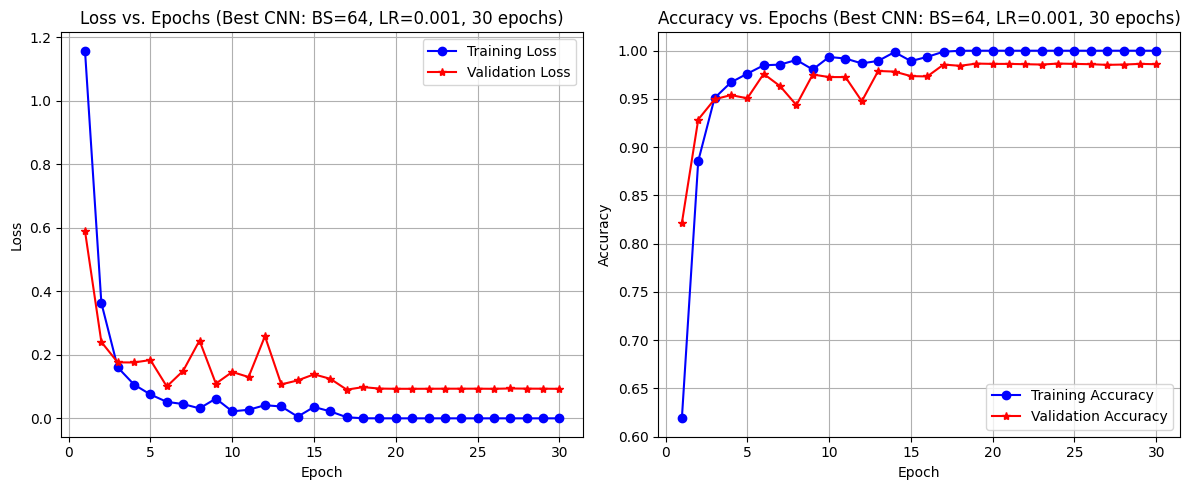

In [17]:
# Use the training results from the 30-epoch training
train_losses = best_cnn_model_results_fullpass["train_losses"]
val_losses = best_cnn_model_results_fullpass["val_losses"]
train_accuracies = best_cnn_model_results_fullpass["train_accuracies"]
val_accuracies = best_cnn_model_results_fullpass["val_accuracies"]

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(12, 5))

# Plot 1: Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, 'bo-', label='Training Loss')
plt.plot(epochs, val_losses, 'r*-', label='Validation Loss')
plt.title(f'Loss vs. Epochs (Best CNN: BS={best_cnn_parameters[0]}, LR={best_cnn_parameters[1]}, 30 epochs)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot 2: Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, 'bo-', label='Training Accuracy')
plt.plot(epochs, val_accuracies, 'r*-', label='Validation Accuracy')
plt.title(f'Accuracy vs. Epochs (Best CNN: BS={best_cnn_parameters[0]}, LR={best_cnn_parameters[1]}, 30 epochs)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

--- Classification Report (Validation Set) ---
              precision    recall  f1-score   support

        Bean       0.99      0.98      0.99       200
Bitter_Gourd       0.99      0.99      0.99       200
Bottle_Gourd       0.99      1.00      1.00       200
     Brinjal       0.98      0.97      0.98       200
    Broccoli       0.98      0.97      0.98       200
     Cabbage       0.97      0.99      0.98       200
    Capsicum       0.99      1.00      0.99       200
      Carrot       1.00      1.00      1.00       200
 Cauliflower       0.98      0.98      0.98       200
    Cucumber       0.98      0.98      0.98       200
      Papaya       0.99      0.98      0.98       200
      Potato       1.00      1.00      1.00       200
     Pumpkin       0.98      0.95      0.97       200
      Radish       0.99      0.99      0.99       200
      Tomato       0.98      0.97      0.98       200

    accuracy                           0.99      3000
   macro avg       0.99      0.99

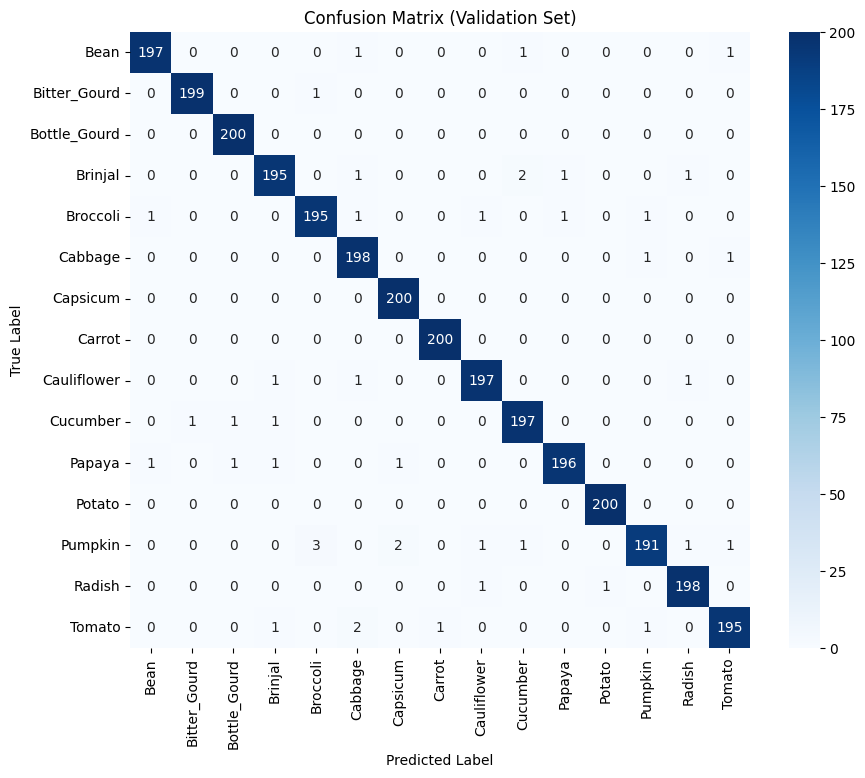

Validation Accuracy: 0.9860


In [18]:
# Re-run validation set to get predictions and labels
best_val_loader = DataLoader(image_datasets['val'], batch_size=32, shuffle=False, num_workers=4) 

val_accuracy, val_preds, val_labels = test(final_best_cnn_model, best_val_loader, device)

# Compute and print metrics
print("--- Classification Report (Validation Set) ---")
print(classification_report(val_labels, val_preds, target_names=class_names))

# Visualize Confusion Matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Validation Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print(f"Validation Accuracy: {val_accuracy:.4f}")

### 1.6 Evaluate the trained model on the test set (5 points)

In [ ]:
## Test the trained model on the test set to evaluate its performance
## Comment on the results

--- Classification Report (Test Set) ---
              precision    recall  f1-score   support

        Bean       0.96      0.98      0.97       200
Bitter_Gourd       0.99      0.98      0.98       200
Bottle_Gourd       0.99      1.00      1.00       200
     Brinjal       0.98      0.97      0.97       200
    Broccoli       0.99      0.97      0.98       200
     Cabbage       0.98      0.98      0.98       200
    Capsicum       0.96      0.99      0.98       200
      Carrot       1.00      1.00      1.00       200
 Cauliflower       0.98      0.98      0.98       200
    Cucumber       0.98      0.97      0.98       200
      Papaya       0.99      0.98      0.99       200
      Potato       1.00      1.00      1.00       200
     Pumpkin       0.98      0.97      0.97       200
      Radish       1.00      1.00      1.00       200
      Tomato       0.98      0.95      0.96       200

    accuracy                           0.98      3000
   macro avg       0.98      0.98      

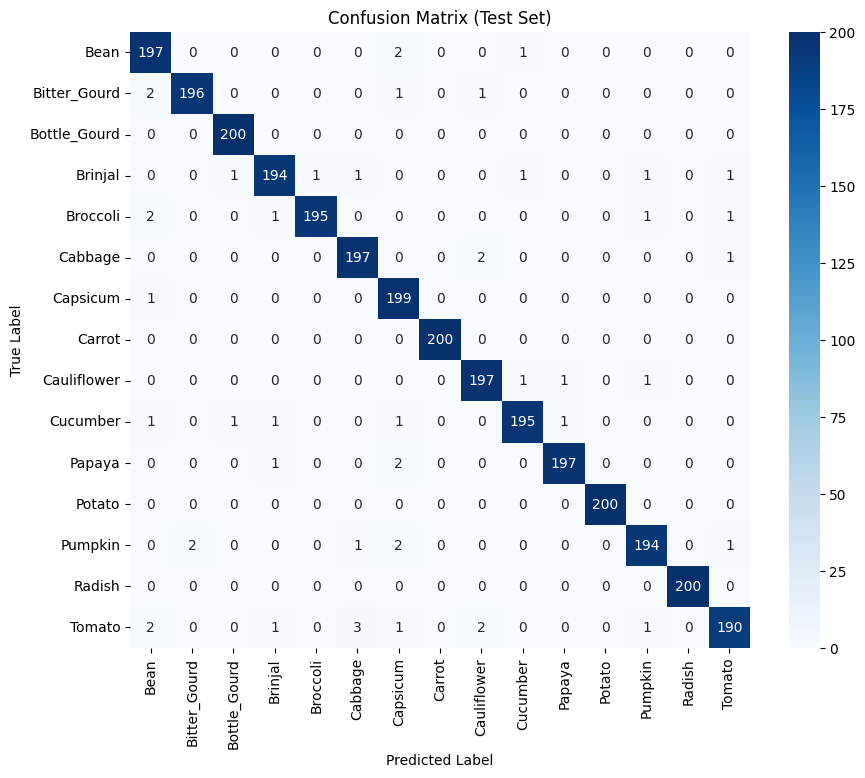

Test Set Accuracy: 0.9837


In [19]:
# Get the test dataloader (you already defined it as 'test' in the dataloaders dict)
test_loader = dataloaders['test']

# Run the test function
test_accuracy, test_preds, test_labels = test(final_best_cnn_model, test_loader, device)

# Compute and print metrics for the test set
print("--- Classification Report (Test Set) ---")
print(classification_report(test_labels, test_preds, target_names=class_names))

# Visualize Confusion Matrix for the test set
cm_test = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Test Set)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

print(f"Test Set Accuracy: {test_accuracy:.4f}")

### 1.7 Conclusion and interpretation (7 points)
* Summarize the performance of the model on the test set
* Discuss any challenges encountered during training and potential areas for improvement
* Reflect on the overall effectiveness of the chosen CNN architecture and training approach

### 1.8 Kaggle Test Result (5 points)
* Put your Kaggle test result for your CNN model here.
* You will get a score between 0-1 and your percentage (e.g. 0.1, 0.3, 0.6, 0.85) of accuracy will be multiplied by the highest possible score (5 points) for this part. That will be your grading score.

In [20]:
import pandas as pd
from PIL import Image
import glob

# Create Kaggle submission file for test data
# Load all test images from the unlabeled test folder
TEST_UNLABELED_DIR = "test_unlabeled_v2"

# Get all test images from the single folder
test_image_paths = []
test_filenames = []

# Get all jpg files from the test_unlabeled_v2 folder
if os.path.exists(TEST_UNLABELED_DIR):
    image_files = glob.glob(os.path.join(TEST_UNLABELED_DIR, "*.jpg"))
    image_files = sorted(image_files)
    
    for img_path in image_files:
        test_image_paths.append(img_path)
        # Extract just the filename (e.g., "img_0001.jpg")
        # For Kaggle, use just the filename, not the full path
        test_filenames.append(os.path.basename(img_path))
    
    print(f"Found {len(test_image_paths)} test images in {TEST_UNLABELED_DIR}")
    print(f"Sample filenames: {test_filenames[:5]}")
else:
    print(f"Error: Directory '{TEST_UNLABELED_DIR}' not found!")

# Create a custom dataset class for test images without labels
class TestImageDataset:
    def __init__(self, image_paths, filenames, transform=None):
        self.image_paths = image_paths
        self.filenames = filenames
        self.transform = transform
    
    def __len__(self):
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        filename = self.filenames[idx]
        
        # Load image
        image = Image.open(img_path).convert('RGB')
        
        # Apply transforms
        if self.transform:
            image = self.transform(image)
        
        return image, filename

# Create test dataset and dataloader
test_dataset = TestImageDataset(test_image_paths, test_filenames, transform=data_transforms['test'])
# Use num_workers=0 on Windows to avoid multiprocessing issues
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Make predictions
final_best_cnn_model.eval()
all_predictions = []
all_filenames = []

with torch.no_grad():
    for images, filenames in test_loader:
        images = images.to(device)
        outputs = final_best_cnn_model(images)
        _, preds = torch.max(outputs, 1)
        
        all_predictions.extend(preds.cpu().numpy())
        all_filenames.extend(filenames)

# Map predicted class indices to class names
predicted_labels = [class_names[pred] for pred in all_predictions]

# Create DataFrame with Id and label columns
submission_df = pd.DataFrame({
    'Id': all_filenames,
    'label': predicted_labels
})

# Sort by filename to ensure consistent ordering
submission_df = submission_df.sort_values('Id').reset_index(drop=True)

# Save to CSV file
submission_file = 'kaggle_submission.csv'
submission_df.to_csv(submission_file, index=False)

print(f"Submission file saved as '{submission_file}'")
print(f"Total predictions: {len(submission_df)}")

Found 750 test images in test_unlabeled_v2
Sample filenames: ['img_0001.jpg', 'img_0002.jpg', 'img_0003.jpg', 'img_0004.jpg', 'img_0005.jpg']
Submission file saved as 'kaggle_submission.csv'
Total predictions: 750


## 2. Exploring Transfer Learning with ResNet50 and MobileNet (60 points)

### 2.1. Introduction
* Brief overview of the task.
* Answer the questions like, What is fine-tuning? Why should we do this? Why do we freeze the rest and train only last layers?

### 2.2. Load the pre-trained ResNet18 model (3 points)


In [ ]:
## Utilize torchvision library to load the pre-trained ResNet50 model
## Ensure that the model's architecture matches ResNet50, by checking the model summary.

### 2.3 Modify the ResNet18 model for transfer learning (15 points)

In [ ]:
## Freeze all layers of the ResNet18 model.
## Replace the final fully connected layer with a new FC layer matching the number of classes
## Unfreeze the final FC layer
## Define appropriate loss function and optimizer for training
## Train the modified ResNet18 model on the vegetable image dataset. (base model)

In [ ]:
## Define another ResNet18 model
## Freeze all layers of the ResNet18 model.
## Replace the final fully connected layer with a new FC layer matching the number of classes
## Unfreeze the final FC layer
## Unfreeze convolutional layers 3 and 4 of the ResNet18 model and again proceed with training. (second model)

In [ ]:
## Define another ResNet18 model
## Replace the final fully connected layer with a new FC layer matching the number of classes proceed with training. (third model)

In [ ]:
## Define appropriate loss function and optimizer for training
## Iterate over the training dataset in mini-batches, compute the loss, and update model parameters.
## Monitor the training process and evaluate all model's performance on the validation set periodically.
## Visualize the accuracy and loss changes of the models across training and validation datasets.

## Compute metrics such as accuracy, precision, recall, and F1-score to assess classification performance.
## Visualize confusion matrix to understand the model's behavior across different classes

Conduct a comparative analysis among these three models. Comment on their performance and select your best model with respect to validation accuracy.
* Which model performed better and why do you think it performed better?  
* Comment on the practical considerations among these models also.

### 2.4 Evaluate the fine-tuned ResNet18 model (5 points)

In [ ]:
## Test the best model on the test set to evaluate its performance.
## Comment on the results
## Compare the fine-tuned ResNet18 model performance with the CNN model implemented from scratch

### 2.5 Kaggle Test Result (5 points)
* Put your Kaggle test result for your ResNet-18 pretrained model here.
* You will get a score between 0-1 and your percentage (e.g. 0.1, 0.3, 0.6, 0.85) of accuracy will be multiplied by the highest possible score (5 points) for this part. That will be your grading score.

### 2.7. Load the pre-trained MobileNet model (3 points)


In [ ]:
## Utilize torchvision library to load the pre-trained MobileNetV2 model
## Ensure that the model's architecture matches MobileNetV2, by checking the model summary.

### 2.8 Modify the MobileNet model for transfer learning (12 points)

In [ ]:
## Freeze all layers of the MobileNet model.
## Replace the final fully connected layer with a new FC layer matching the number of classes
## Unfreeze the final FC layer
## Define appropriate loss function and optimizer for training
## Train the modified MobileNet model on the vegetable image dataset. (base model)

In [ ]:
## Define another MobileNet model
## Replace the final fully connected layer with a new FC layer matching the number of classes proceed with training. (second model)

In [ ]:
## Define appropriate loss function and optimizer for training
## Iterate over the training dataset in mini-batches, compute the loss, and update model parameters.
## Monitor the training process and evaluate all model's performance on the validation set periodically.
## Visualize the accuracy and loss changes of the models across training and validation datasets.

## Compute metrics such as accuracy, precision, recall, and F1-score to assess classification performance.
## Visualize confusion matrix to understand the model's behavior across different classes

Conduct a comparative analysis among these two models. Comment on their performance and select your best model with respect to validation accuracy.
* Which model performed better and why do you think it performed better?  
* Comment on the practical considerations among these models also.

### 2.9 Evaluate the fine-tuned MobileNet model (5 points)

In [ ]:
## Test the best model on the test set to evaluate its performance.
## Comment on the results

In [ ]:
## Compare the best fine-tuned MobileNet model performance with the best CNN model implemented from scratch
## Compare the best fine-tuned MobileNet model performance with the best ResNet18 model implemented from scratch

### 2.10 Kaggle Test Result (5 points)
* Put your Kaggle test result for your MobileNet pretrained model here.
* You will get a score between 0-1 and your percentage (e.g. 0.1, 0.3, 0.6, 0.85) of accuracy will be multiplied by the highest possible score (5 points) for this part. That will be your grading score.

## 3 Analyze advantages and disadvantages (7 points)

* Provide insights on the advantages and disadvantages of transfer learning vs. training from scratch
* Put a table for comparison of the best 3 models that you have obtained in this assignment (CNN from scratch, ResNet18, MobileNet)
* Discuss practical considerations when choosing between these approaches and models.

